# Этап 2. Проведение исследовательского анализа данных и логирование Jupyter Notebook с EDA в MLflow

Возьмем очищенный датасет из прошлого задания и проведем более глубокий анализ, чтобы лучше понять характеристики и взаимосвязи данных.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import sqlite3
import pandas as pd

In [ ]:
DATA_DIR = Path("baseline/data")

if not DATA_DIR.is_dir():
    DATA_DIR = Path("../baseline/data")

df_clean = pd.read_parquet(DATA_DIR / "flats_clean.parquet")

print("Размер:", df_clean.shape)
display(df_clean.head())

Размер: (141206, 19)


,flat_id,building_id,floor,rooms,price,build_year,building_type_int,flats_count,floors_total,kitchen_area,living_area,total_area,latitude,longitude,ceiling_height,is_apartment,studio,has_elevator,area_sum_conflict
0,0,6220,9,1,9500000,1965,6,84,12,9.9,19.900000,35.099998,55.717113,37.781120,2.64,False,False,True,0
1,1,18012,7,1,13500000,2001,2,97,10,NaN,16.600000,43.000000,55.794849,37.608013,3.00,False,False,True,0
2,2,17821,9,2,13500000,2000,4,80,10,9.0,32.000000,56.000000,55.740040,37.761742,2.70,False,False,True,0
3,3,18579,1,3,20000000,2002,4,771,17,10.1,43.099998,76.000000,55.672016,37.570877,2.64,False,False,True,0
4,4,9293,3,1,5200000,1971,1,208,9,3.0,14.000000,24.000000,55.808807,37.707306,2.60,False,False,True,0


## 2. Проверка данных

Проверим типы столбцов, количество пропусков,полные дубликаты и повторения

In [10]:
summary = pd.DataFrame({
    "Тип данных": df_clean.dtypes.astype(str),
    "Пропуски, шт.": df_clean.isna().sum(),
    "Пропуски, %": df_clean.isna().mean().mul(100).round(2),
    "Количество разных значений (не строк)": df_clean.nunique(),
})

display(summary)


checks = pd.Series({
    "Полные дубликаты": int(df_clean.duplicated().sum()),
    "Повторяющиеся flat_id": int(df_clean["flat_id"].duplicated().sum()),
    "Цена < 1 млн": int(df_clean["price"].lt(1_000_000).sum()),
    "Общая площадь <= 0": int(df_clean["total_area"].le(0).sum()),
    "Строки с конфликтом площадей": int(
        df_clean["area_sum_conflict"].eq(1).sum()
    ),
}, name="Количество строк")

display(checks.to_frame())


conflict_counts = (
    df_clean["area_sum_conflict"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
    .rename_axis("Значение флага")
    .reset_index(name="Количество строк")
)

conflict_counts["Конфликт"] = conflict_counts["Значение флага"].map({
    0: "Нет",
    1: "Да",
})

display(
    conflict_counts[
        ["Значение флага", "Конфликт", "Количество строк"]
    ]
)

,Тип данных,"Пропуски, шт.","Пропуски, %",Количество разных значений (не строк)
flat_id,int64,0,0.00,141206
building_id,int64,0,0.00,24589
floor,int64,0,0.00,56
rooms,int64,0,0.00,14
price,int64,0,0.00,8298
build_year,int64,0,0.00,118
building_type_int,int64,0,0.00,7
flats_count,int64,0,0.00,706
floors_total,int64,0,0.00,64
kitchen_area,float64,11668,8.26,1034


,Количество строк
Полные дубликаты,0
Повторяющиеся flat_id,0
Цена < 1 млн,0
Общая площадь <= 0,0
Строки с конфликтом площадей,122


,Значение флага,Конфликт,Количество строк
0,0,Нет,141084
1,1,Да,122


### Вывод

Датасет содержит 141 206 строк и 19 столбцов.

- Полные дубликаты и повторяющиеся flat_id отсутствуют.
- Цены ниже 1 млн и неположительные значения общей площади отсутствуют.
- Некорректные значения площади кухни, жилой площади и высоты потолков
  заменены пропусками.
- Пропуски сохранены: kitchen_area — 11 668, living_area — 18 561,   ceiling_height — 29.
- Для 122 строк есть флаг противоречия суммы площадей  area_sum_conflict.


In [14]:
%pip install seaborn

   ---------------------------------------- 0.0/294.9 kB ? eta -:--:--
   ---- ----------------------------------- 30.7/294.9 kB ? eta -:--:--
   --------- ----------------------------- 71.7/294.9 kB 777.7 kB/s eta 0:00:01
   --------------- ---------------------- 122.9/294.9 kB 901.1 kB/s eta 0:00:01
   ------------------------------ --------- 225.3/294.9 kB 1.4 MB/s eta 0:00:01
   -------------------------------------- - 286.7/294.9 kB 1.4 MB/s eta 0:00:01
   ---------------------------------------- 294.9/294.9 kB 1.3 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

df_eda = df_clean.copy()

print("Размер набора для EDA:", df_eda.shape)

Размер набора для EDA: (141206, 19)


### Целевая переменная

Целевая переменная — price, цена квартиры в рублях.

Смотрим статистику цены, затем строим гистограммы цены в исходном и логарифмическом масштабе.

In [16]:
price_stats = df_eda["price"].describe(
    percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
).to_frame(name="Цена, руб.")

display(price_stats.round(2))

print(f"Асимметрия: {df_eda['price'].skew():.2f}")

,"Цена, руб."
count,1.412060e+05
mean,1.946304e+07
std,6.630301e+07
min,1.000000e+06
1%,5.300000e+06
5%,6.500000e+06
25%,8.950000e+06
50%,1.189000e+07
75%,1.695000e+07
95%,4.950000e+07


Асимметрия: 88.93


### Вывод

У цены выраженная правосторонняя асимметрия: основная часть квартир стоит значительно меньше отдельных очень дорогих объектов. Значение асимметрии 88.93 подтверждает длинный правый хвост распределения, поэтому экстремальные значения могут сильно влиять и на этот показатель, и на среднее.
Среднее где-то в 1,64 раза выше медианы. При этом центральные 50% наблюдений находятся между 8,95 и 16,95 млн руб., а максимальная цена достигает почти 9,87 млрд руб.
Очень большой разброс максимума, такие дорогие объекты требуют отдельного изучения, чтобы принять решение нужно удалять или нет


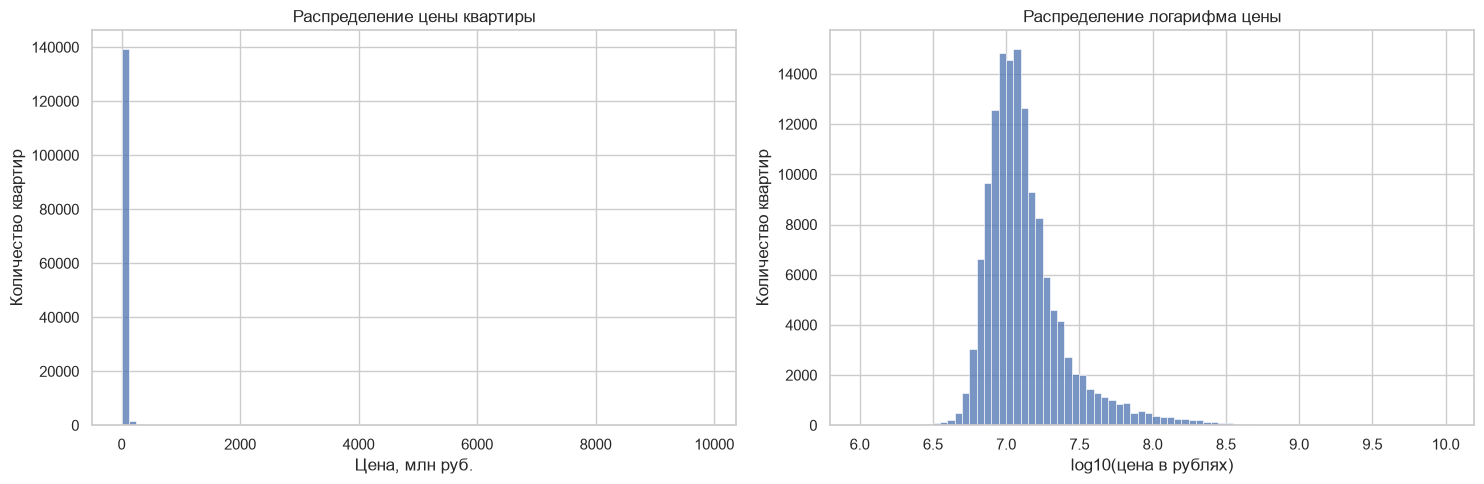

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(
    x=df_eda["price"] / 1_000_000,
    bins=80,
    ax=axes[0],
)
axes[0].set_title("Распределение цены квартиры")
axes[0].set_xlabel("Цена, млн руб.")
axes[0].set_ylabel("Количество квартир")

sns.histplot(
    x=np.log10(df_eda["price"]),
    bins=80,
    ax=axes[1],
)
axes[1].set_title("Распределение логарифма цены")
axes[1].set_xlabel("log10(цена в рублях)")
axes[1].set_ylabel("Количество квартир")

plt.tight_layout()
plt.show()

На гистограмме мы видим также правостороннюю ассиметрию, как и в таблицах.
Гистограмма цены в исходном виде плохо показывает структуру основной части данных: крайне дорогие объекты растягивают горизонтальную ось.

В логарифмическом масштабе основная часть распределения видна лучше.  По графику нельзя утверждать, что логарифм цены имеет нормальное распределение.


Смотрим какие объекты дают правый хвост и ассиметрию

In [19]:
cols = [
    "flat_id",
    "building_id",
    "price",
    "total_area",
    "living_area",
    "kitchen_area",
    "rooms",
    "floor",
    "floors_total",
    "area_sum_conflict",
]

top_expensive = df_eda.nlargest(10, "price")[cols].copy()

top_expensive["Цена, млн руб."] = (
    top_expensive["price"] / 1_000_000
).round(2)

top_expensive["Цена за м², руб."] = (
    top_expensive["price"] / top_expensive["total_area"]
).round(0)

display(top_expensive)

,flat_id,building_id,price,total_area,living_area,kitchen_area,rooms,floor,floors_total,area_sum_conflict,"Цена, млн руб.","Цена за м², руб."
85703,85787,19982,9873737728,220.0,125.0,22.299999,5,25,33,0,9873.74,44880626.0
83694,83773,6108,9799999488,37.0,22.0,8.000000,2,6,9,0,9800.00,264864851.0
40837,40855,10733,9200000000,45.0,27.9,6.000000,2,2,9,0,9200.00,204444444.0
117965,118083,22134,8147034112,208.0,NaN,NaN,4,6,8,0,8147.03,39168433.0
50431,50455,22418,4686425088,103.0,NaN,NaN,3,5,14,0,4686.43,45499273.0
79190,79266,21192,4447152128,120.0,65.0,20.000000,4,6,13,0,4447.15,37059601.0
58748,58778,187,4048056064,202.0,NaN,NaN,7,2,2,0,4048.06,20039882.0
79188,79264,23762,3525904640,97.0,70.0,14.000000,3,21,25,0,3525.90,36349532.0
14427,14433,21226,2551801088,925.0,NaN,NaN,10,8,22,0,2551.80,2758704.0
115164,115280,21226,2551801088,925.0,NaN,NaN,10,8,22,0,2551.80,2758704.0


В таблице можно заметить подозрительные цены.

Есть квартиры небольшой площади с экстремальными ценами: 37 м2 за 9,8 млрд руб. и 45 м2 за 9,2 млрд руб.
Цена квадратного метра составляет около 264,86 и 204,44 млн руб.соответственно.

Таким образом, крайние значения цены не объясняются только большой площадью. Возможны ошибки исходных данных, однако подтвердить их причину пока нельзя.

У двух объектов площадью 925 м² совпадают показанные характеристики, но различаются flat_id. Это требует отдельной проверки возможных
повторов без учёта идентификатора квартиры.

Теперь посмотрим связь цены и площади.
Для изучения связи построим диаграммы рассеяния в исходном и логарифмическом масштабе. Для читаемости графиков используем случайную выборку до 10 000 объектов.Корреляции рассчитаем на всём наборе.

Сравним коэффициенты Пирсона и Спирмен для корреляции.

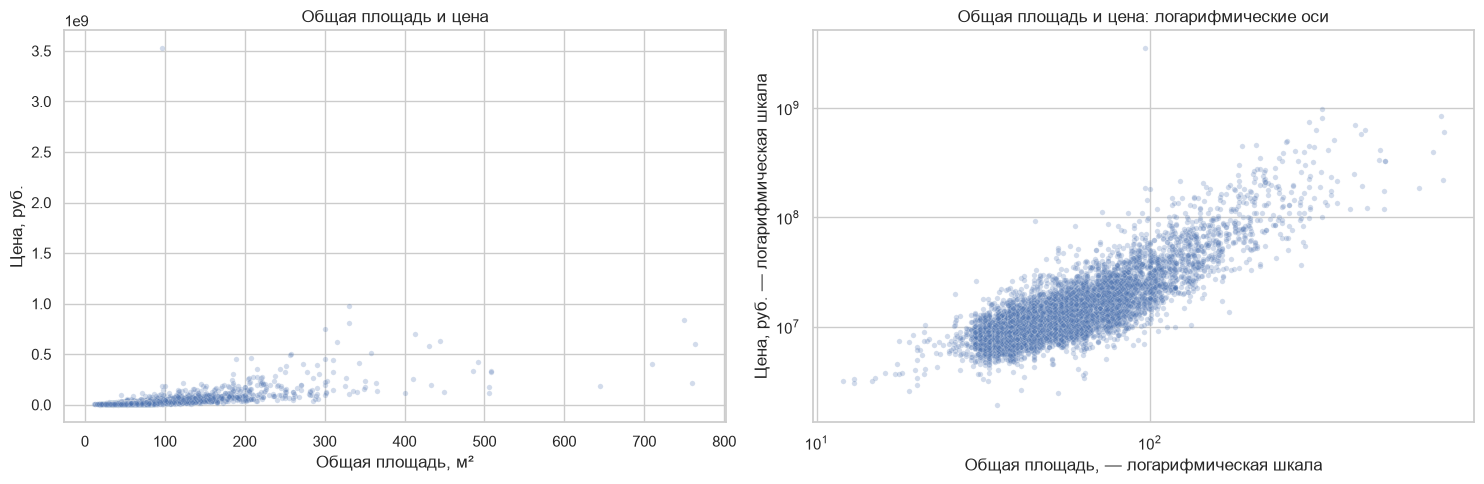

,Связь общей площади с ценой
Корреляция Пирсона,0.421
Корреляция Спирмена,0.765


In [20]:
plot_sample = df_eda.sample(
    n=min(10_000, len(df_eda)),
    random_state=42,
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.scatterplot(
    data=plot_sample,
    x="total_area",
    y="price",
    alpha=0.25,
    s=15,
    ax=axes[0],
)
axes[0].set_title("Общая площадь и цена")
axes[0].set_xlabel("Общая площадь, м²")
axes[0].set_ylabel("Цена, руб.")

sns.scatterplot(
    data=plot_sample,
    x="total_area",
    y="price",
    alpha=0.25,
    s=15,
    ax=axes[1],
)
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_title("Общая площадь и цена: логарифмические оси")
axes[1].set_xlabel("Общая площадь, — логарифмическая шкала")
axes[1].set_ylabel("Цена, руб. — логарифмическая шкала")

plt.tight_layout()
plt.show()

area_price_corr = pd.Series({
    "Корреляция Пирсона": df_eda["total_area"].corr(
        df_eda["price"], method="pearson"
    ),
    "Корреляция Спирмена": df_eda["total_area"].corr(
        df_eda["price"], method="spearman"
    ),
}, name="Связь общей площади с ценой")

display(area_price_corr.round(3).to_frame())

### Вывод

Площадь связана с ценой, но не определяет её однозначно: при похожих площадях цены заметно различаются.

Отдельные объекты находятся значительно выше основного облака точек — их цена слишком высока относительно площади.

В исходном масштабе экстремальные цены очень сложно изучить, в логарифмических координатах основное облако наблюдений имеет выраженное
восходящее направление. При этом квартиры близкой площади могут заметно различаться по цене, поэтому для прогнозирования необходимо исследовать и другие характеристики.

Корреляция общей площади с ценой составляет:
- Пирсона — 0,421
- Спирмена — 0,765

Линейная связь в исходном масштабе выражена слабее. Различие коэффициентов согласуется с наличием экстремальных цен и возможной нелинейностью связи, но не позволяет однозначно определить причину.

Общая площадь является перспективным признаком для прогнозирования. При моделировании следует сравнить варианты преобразования площади
и целевой переменной, оценивая результат на валидации.

Теперь посмотрим остальные числовые характеристики и распределение.

Изучим общую, жилую и кухонную площади, высоту потолков, год постройки и этажность зданий. Рассмотрим описательные статистики и гистограммы.

Пропуски не заполняем.

,count,mean,std,min,1%,50%,95%,99%,max
total_area,141206.0,62.39,40.31,11.0,29.00,53.00,127.1,224.0,960.3
living_area,122645.0,35.76,22.22,2.0,14.00,31.00,70.0,123.0,700.0
kitchen_area,129538.0,9.81,4.71,1.5,5.00,9.00,18.0,30.0,203.0
ceiling_height,141177.0,2.75,0.21,2.0,2.48,2.64,3.1,3.4,5.0
build_year,141206.0,1986.61,22.14,1901.0,1926.00,1985.00,2017.0,2019.0,2023.0
floors_total,141206.0,14.11,6.90,1.0,4.00,14.00,25.0,40.0,99.0


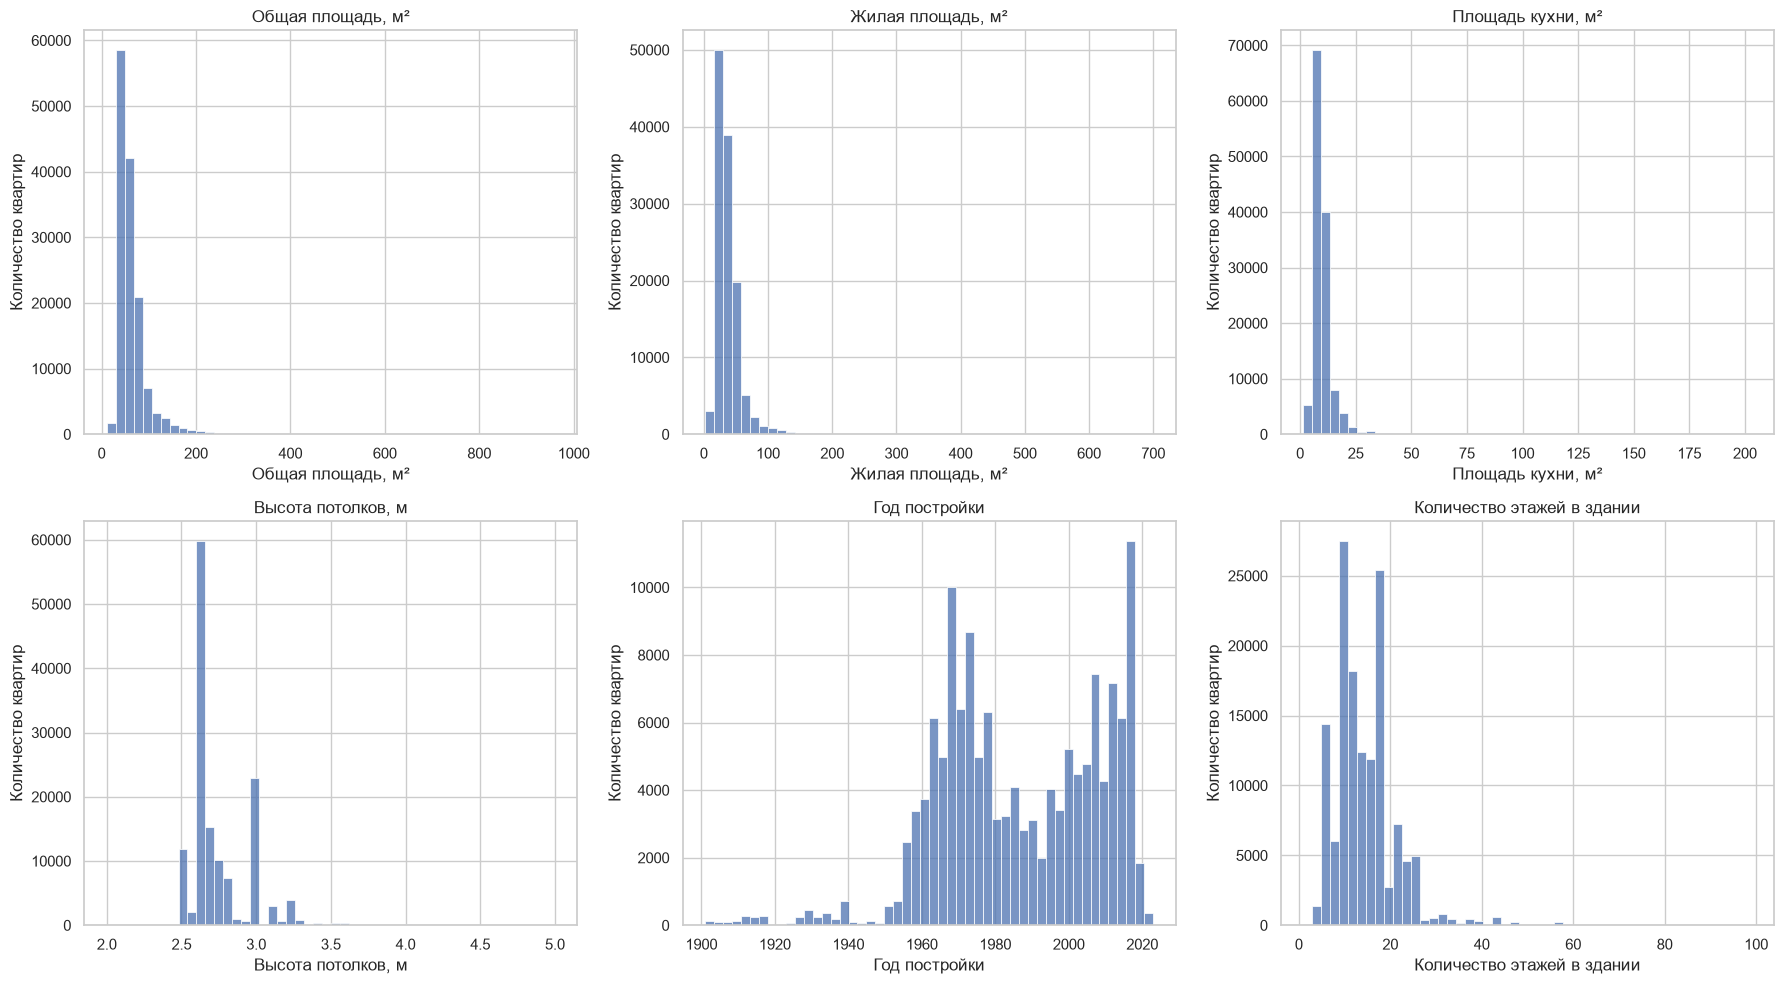

In [21]:
numeric_features = [
    "total_area",
    "living_area",
    "kitchen_area",
    "ceiling_height",
    "build_year",
    "floors_total",
]

display(
    df_eda[numeric_features]
    .describe(percentiles=[0.01, 0.5, 0.95, 0.99])
    .T
    .round(2)
)

feature_labels = {
    "total_area": "Общая площадь, м²",
    "living_area": "Жилая площадь, м²",
    "kitchen_area": "Площадь кухни, м²",
    "ceiling_height": "Высота потолков, м",
    "build_year": "Год постройки",
    "floors_total": "Количество этажей в здании",
}

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, feature in zip(axes.flat, numeric_features):
    sns.histplot(
        x=df_eda[feature].dropna(),
        bins=50,
        ax=ax,
    )
    ax.set_title(feature_labels[feature])
    ax.set_xlabel(feature_labels[feature])
    ax.set_ylabel("Количество квартир")

plt.tight_layout()
plt.show()

### Вывод

Распределения всех (кухонной, жилой и т.п.)площадей имеют правостороннюю асимметрию. Медианные значения составляют 53, 31 и 9 м2 соответственно.
Максимальные значения значительно превышают 99-е процентили.

Медианная высота потолков составляет 2,64 м. В распределении видны выраженные пики на отдельных значениях. После очистки сохраняются
29 пропусков.

Годы постройки находятся в диапазоне 1901–2023, медиана — 1985 год. Распределение неоднородно.

Медианная этажность здания составляет 14, максимальная — 99. Гистограмма отражает количество квартир в зданиях соответствующей
этажности.

Статистики жилой площади, площади кухни и высоты потолков рассчитаны по доступным значениям. 

Теперь для каждого признака надо посмотреть  корреляции Пирсона и Спирмена с ценой. Также посмотрим число наблюдений, использованных при расчёте: из-за пропусков оно может различаться между признаками.

,Наблюдений,Пирсон,Спирмен
Признак,,,
total_area,141206,0.421,0.765
living_area,122645,0.326,0.701
rooms,141206,0.258,0.651
ceiling_height,141177,0.239,0.493
kitchen_area,129538,0.217,0.477
floors_total,141206,0.023,0.196
build_year,141206,0.056,0.186
floor,141206,0.027,0.148
flats_count,141206,-0.041,0.001


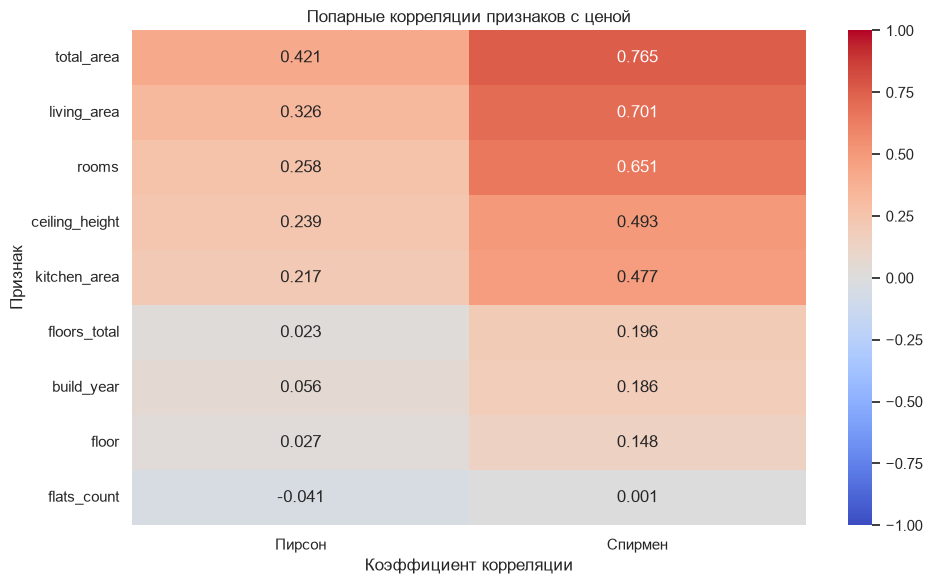

In [22]:
features = [
    "total_area",
    "living_area",
    "kitchen_area",
    "rooms",
    "ceiling_height",
    "floor",
    "floors_total",
    "build_year",
    "flats_count",
]

corr_rows = []

for feature in features:
    pair = df_eda[[feature, "price"]].dropna()

    corr_rows.append({
        "Признак": feature,
        "Наблюдений": len(pair),
        "Пирсон": pair[feature].corr(
            pair["price"], method="pearson"
        ),
        "Спирмен": pair[feature].corr(
            pair["price"], method="spearman"
        ),
    })

price_correlations = (
    pd.DataFrame(corr_rows)
    .set_index("Признак")
    .sort_values("Спирмен", ascending=False)
)

display(price_correlations.round(3))

plt.figure(figsize=(10, 6))

sns.heatmap(
    price_correlations[["Пирсон", "Спирмен"]],
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
)

plt.title("Попарные корреляции признаков с ценой")
plt.xlabel("Коэффициент корреляции")
plt.ylabel("Признак")
plt.tight_layout()
plt.show()

Среди всех  признаков наибольшая корреляция Спирмена с ценой видна у общей площади (0,765), жилой площади (0,701) и количества комнат (0,651).

Высота потолков (0,493) и площадь кухни (0,477) также имеют положительную ранговую связь с ценой.

У этажности здания (0,196), года постройки (0,186) и этажа квартиры (0,148)  связь с ценой значительно слабее.
У количества квартир в здании она практически отсутствует (0,001).

Эти результаты описывают  связи, а не непосредственный вклад каждого признака. Низкая корреляция сама по себе не является основанием
для исключения признака из модели.

Рассмотрим количество наблюдений и медианную цену в каждой группе. Затем построим диаграммы размаха цены.

Для читаемости графиков используем логарифмическую шкалу цены. Точки за пределами усов не показываем, но из данных их не удаляем.


Группировка по rooms:


,Количество,"Медиана, млн руб.","Среднее, млн руб."
rooms,,,
1,41947,8.50,9.32
2,52622,11.75,14.13
3,36915,16.00,22.55
4,7088,32.90,54.18
5,1800,72.00,118.01
6,556,130.00,177.65
7,179,150.00,259.49
8,55,268.85,336.52
9,18,236.69,382.34



Группировка по building_type_int:


,Количество,"Медиана, млн руб.","Среднее, млн руб."
building_type_int,,,
0,1926,12.00,27.52
1,23126,14.50,22.85
2,25246,19.99,35.56
3,1773,46.72,124.60
4,78608,10.65,11.92
5,4,8.50,8.15
6,10523,9.70,10.56


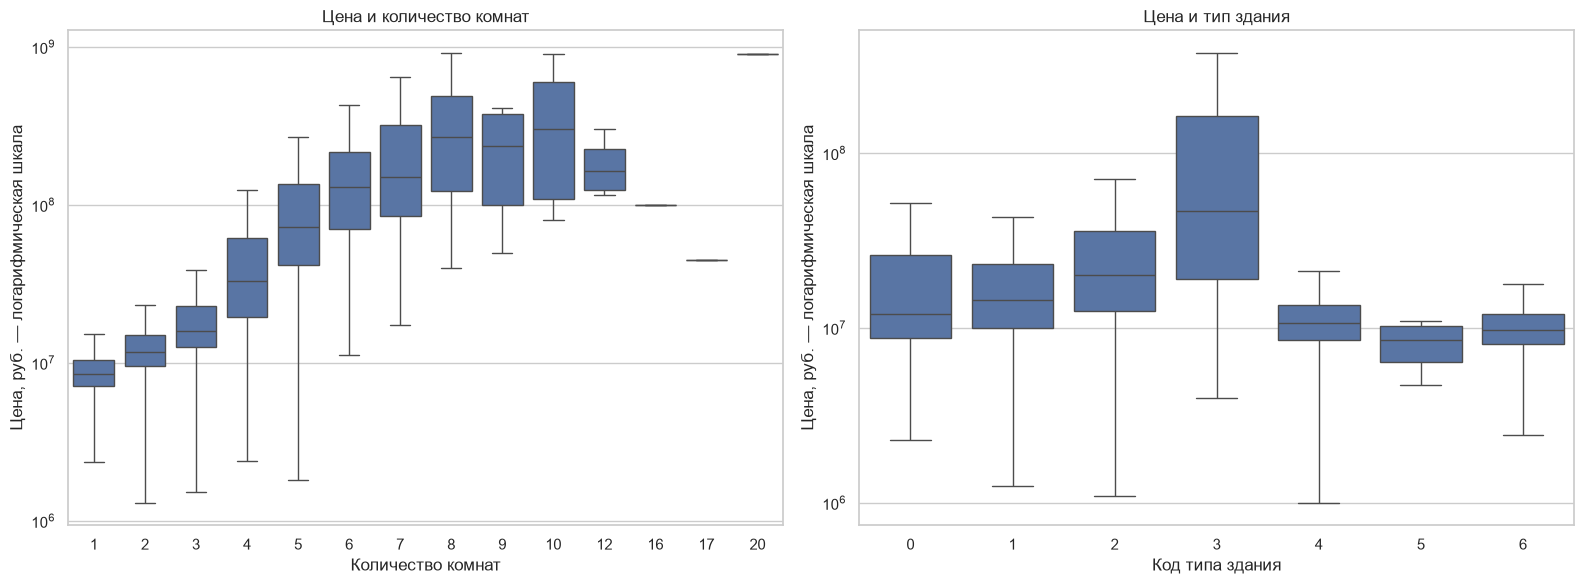

In [23]:
for feature in ["rooms", "building_type_int"]:
    group_stats = (
        df_eda.groupby(feature)["price"]
        .agg(
            Количество="size",
            Медиана="median",
            Среднее="mean",
        )
        .sort_index()
    )

    group_stats["Медиана, млн руб."] = (
        group_stats["Медиана"] / 1_000_000
    ).round(2)

    group_stats["Среднее, млн руб."] = (
        group_stats["Среднее"] / 1_000_000
    ).round(2)

    print(f"\nГруппировка по {feature}:")
    display(
        group_stats[
            ["Количество", "Медиана, млн руб.", "Среднее, млн руб."]
        ]
    )


fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, feature, title, xlabel in [
    (axes[0], "rooms", "Цена и количество комнат", "Количество комнат"),
    (
        axes[1],
        "building_type_int",
        "Цена и тип здания",
        "Код типа здания",
    ),
]:
    sns.boxplot(
        data=df_eda,
        x=feature,
        y="price",
        order=sorted(df_eda[feature].dropna().unique()),
        showfliers=False,
        ax=ax,
    )

    ax.set_yscale("log")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Цена, руб. — логарифмическая шкала")

plt.tight_layout()
plt.show()

#### Вывод 

В массовых группах медианная цена растёт с количеством комнат:
для 1-комнатных квартир она составляет 8,50 млн руб.,
для 2-комнатных — 11,75 млн руб, 
для 3-комнатных — 16 млн руб,
для 4-комнатных — 32,90 млн руб.

Группы сильно различаются по размеру. Для квартир с 16, 17 и 20 комнатами есть лишь по одному наблюдению, поэтому их цены не позволяют сделать выводы о таких объектах.

Медианные цены различаются и между кодами типа здания: для типа 3 медиана составляет 46,72 млн руб., для типа 2 — 19,99 млн руб.,
для наиболее массового типа 4 — 10,65 млн руб. Тип 5 представлен только четырьмя наблюдениями.

Различия между группами не доказывают самостоятельного влияния количества комнат или типа здания.

### Взаимосвязи характеристик

Рассмотрим корреляции Спирмена между общей, жилой и кухонной площадями, количеством комнат и высотой потолков.

Цель — выявить признаки, которые могут частично описывать одни и те же свойства квартиры.

,total_area,living_area,kitchen_area,rooms,ceiling_height
total_area,1.000,0.933,0.553,0.870,0.448
living_area,0.933,1.000,0.362,0.917,0.299
kitchen_area,0.553,0.362,1.000,0.238,0.487
rooms,0.870,0.917,0.238,1.000,0.219
ceiling_height,0.448,0.299,0.487,0.219,1.000


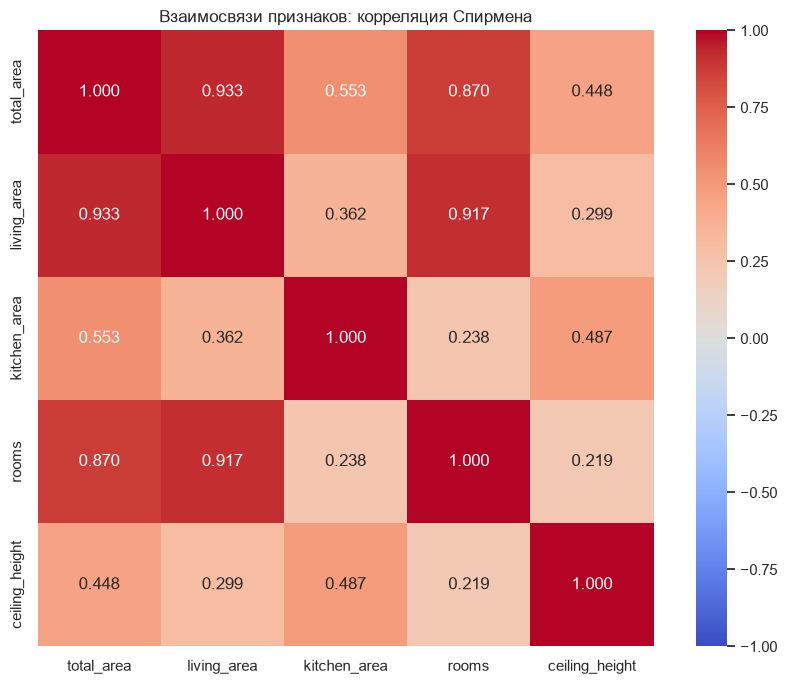

In [24]:
related_features = [
    "total_area",
    "living_area",
    "kitchen_area",
    "rooms",
    "ceiling_height",
]

feature_corr = df_eda[related_features].corr(method="spearman")

display(feature_corr.round(3))

plt.figure(figsize=(9, 7))

sns.heatmap(
    feature_corr,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
)

plt.title("Взаимосвязи признаков: корреляция Спирмена")
plt.tight_layout()
plt.show()

#### Взаимосвязи 

Выявлена сильная положительная  связь между общей и жилой площадями (0,933), жилой площадью и количеством комнат (0,917),
общей площадью и количеством комнат (0,870).

Эти признаки частично отражают одну характеристику — размер квартиры. Поэтому их связи с ценой нельзя интерпретировать как независимые эффекты.

При построении линейных моделей следует дополнительно проверить мультиколлинеарность.

Для выбранных числовых признаков рассчитаем коэффициент увеличения дисперсии — VIF.

В отличие от попарной корреляции, VIF учитывает линейную связь каждого признака со всеми остальными признаками выбранного набора.

Цену, идентификаторы и числовые коды категорий в расчёт не включаем.


In [26]:
%pip install statsmodels

   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB 388.9 kB/s eta 0:00:30
   ---------------------------------------- 0.1/11.4 MB 491.5 kB/s eta 0:00:23
   ---------------------------------------- 0.1/11.4 MB 521.8 kB/s eta 0:00:22
   ---------------------------------------- 0.1/11.4 MB 479.3 kB/s eta 0:00:24
    --------------------------------------- 0.1/11.4 MB 500.5 kB/s eta 0:00:23
    --------------------------------------- 0.2/11.4 MB 482.7 kB/s eta 0:00:24
    --------------------------------------- 0.2/11.4 MB 512.0 kB/s eta 0:00:22
    --------------------------------------- 0.2/11.4 MB 509.6 kB/s eta 0:00:22
    --------------------------------------- 0.2/11.4 MB 514.3 kB/s eta 0:00:22
    --------------------------------------- 0.3/11.4 MB 532.5 kB/s eta 0:00:21
   - -------------------------------------- 0.3/11.4 MB 527.5 kB/s eta


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [27]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_features = [
    "total_area",
    "living_area",
    "kitchen_area",
    "rooms",
    "ceiling_height",
    "floor",
    "floors_total",
    "build_year",
    "flats_count",
]

X_vif = (
    df_eda[vif_features]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
    .astype(float)
)

print("Строк в исходном наборе:", len(df_eda))
print("Строк для расчёта VIF:", len(X_vif))
print(
    "Исключено из расчёта из-за пропусков:",
    len(df_eda) - len(X_vif),
)

constant_features = X_vif.columns[X_vif.std().eq(0)].tolist()

if constant_features:
    raise ValueError(
        f"Обнаружены постоянные признаки: {constant_features}"
    )

X_scaled = (X_vif - X_vif.mean()) / X_vif.std()

X_with_const = sm.add_constant(X_scaled, has_constant="add")

vif_table = pd.DataFrame({
    "Признак": X_scaled.columns,
    "VIF": [
        variance_inflation_factor(
            X_with_const.to_numpy(),
            X_with_const.columns.get_loc(feature),
        )
        for feature in X_scaled.columns
    ],
}).sort_values("VIF", ascending=False)

display(vif_table.round(2).reset_index(drop=True))

Строк в исходном наборе: 141206
Строк для расчёта VIF: 119383
Исключено из расчёта из-за пропусков: 21823


,Признак,VIF
0,total_area,14.23
1,living_area,12.94
2,rooms,3.16
3,floors_total,2.55
4,kitchen_area,2.26
5,build_year,2.01
6,floor,1.55
7,ceiling_height,1.37
8,flats_count,1.29


Проверка выявила мультиколлинеарность в выбранном наборе: VIF общей площади — 14.23, жилой — 12.94. Оба значения заметно выше ориентира 5, который используют для выявления высокой линейной зависимости признака от остальных. У других рассмотренных признаков VIF ниже 5. 

Расчёт выполнен не на всей выборке, а на 119 383 строках без пропусков. Поэтому вывод относится к этой подвыборке, а не автоматически ко всему набору после будущего заполнения пропусков.

Проверим диагностический вариант без living_area, т.к. у неё высокая связь с общей площадью, она чаще содержит пропуски, общую площадь пока оставим как основную характеристику размера квартиры.

In [28]:
X_reduced = X_vif.drop(columns=["living_area"])

X_reduced_scaled = (
    (X_reduced - X_reduced.mean()) / X_reduced.std()
)

X_reduced_const = sm.add_constant(
    X_reduced_scaled,
    has_constant="add",
)

vif_reduced = pd.DataFrame({
    "Признак": X_reduced_scaled.columns,
    "VIF без living_area": [
        variance_inflation_factor(
            X_reduced_const.to_numpy(),
            X_reduced_const.columns.get_loc(feature),
        )
        for feature in X_reduced_scaled.columns
    ],
})

vif_comparison = (
    vif_table.rename(columns={"VIF": "VIF исходный"})
    .merge(vif_reduced, on="Признак", how="left")
    .sort_values("VIF исходный", ascending=False)
    .reset_index(drop=True)
)

print("Строк в обоих расчётах:", len(X_reduced))
display(vif_comparison.round(2))

Строк в обоих расчётах: 119383


,Признак,VIF исходный,VIF без living_area
0,total_area,14.23,4.22
1,living_area,12.94,NaN
2,rooms,3.16,2.78
3,floors_total,2.55,2.55
4,kitchen_area,2.26,2.16
5,build_year,2.01,1.97
6,floor,1.55,1.55
7,ceiling_height,1.37,1.37
8,flats_count,1.29,1.29


Выявлена сильная положительная связь между общей и жилой площадями (0,933), жилой площадью и количеством комнат (0,917), общей площадью и количеством комнат (0,870).

Эти признаки отражают одну характеристику — размер квартиры. Поэтому их связи с ценой нельзя интерпретировать как независимые эффекты.

При построении линейных моделей следует дополнительно проверить мультиколлинеарность и рассмотреть регуляризацию.  Выбор набора признаков будем проверять на валидации.

## Итоговый вывод 

### 1. Цена имеет выраженную правостороннюю асимметрию

Медианная цена составляет 11,89 млн руб., средняя — 19,46 млн руб.Коэффициент асимметрии равен 88,93. Максимальная цена достигает
около 9,87 млрд руб., тогда как 99-й процентиль — около 152,13 млн руб.

Встречаются квартиры небольшой площади с экстремальными ценами:37 м2 за 9,8 млрд руб. и 45 м2 за 9,2 млрд руб.

Последствие для моделирования: проверить вариант с логарифмом цены и сравнить качество с моделью на исходной целевой переменной.
Отдельно оценить ошибки на дорогих объектах.

### 2. Площадь и количество комнат связаны с ценой

Корреляции Спирмена с ценой составляют:
- общая площадь — 0,765;
- жилая площадь — 0,701;
- количество комнат — 0,651.

Медианная цена увеличивается от 8,50 млн руб. для однокомнатных квартир до 11,75 млн руб. для двухкомнатных и 16 млн руб. для трёхкомнатных.

Это значит, что можно использовать характеристики размера квартиры как потенциально полезные признаки. Попарные корреляции
не считать оценками независимого вклада признаков.

### 3. Характеристики размера квартиры сильно связаны между собой

Общая площадь, жилая площадь и количество комнат сильно связаны: корреляции Спирмена между ними составляют от 0,870 до 0,933.

Дополнительная проверка VIF на 119 383 полных наблюдениях выявила высокие значения для общей площади (14,23) и жилой площади (12,94).

После исключения living_area из расчёта на тех же строках VIF общей площади снизился до 4,22. У всех оставшихся признаков VIF ниже 5.

Значит нужно проверить линейную модель без living_area и сравнить её с регуляризованным вариантом на полном наборе признаков.
Не считать снижение VIF доказательством улучшения качества прогноза, сначала проверим это  на валидации.

### 4. Типы зданий различаются по ценам и числу наблюдений

Медианная цена для типа здания 3 составляет 46,72 млн руб, для типа 2 — 19,99 млн руб, для наиболее массового типа 4 — 10,65 млн руб.

Тип 5 представлен только четырьмя наблюдениями. 
Среди квартир с 16, 17 и 20 комнатами есть лишь по одному объекту в каждой группе.

Значит нужно рассматривать building_type_int как категориальный признак и учитывать редкие группы.
Различия медиан не доказывают самостоятельного влияния: группы могут различаться по площади, расположению и другим параметрам.

### 5. После очистки остаются пропуски и отмеченные противоречия

Пропуски присутствуют в площади кухни — 11 668 (8,26%), жилой площади — 18 561 (13,14%) и высоте потолков — 29 (0,02%).

Для 122 строк установлен флаг area_sum_conflict. В ходе EDA эти строки сохранены.

Значит нужно выбрать способ обработки пропусков с учётом модели. Если используется заполнение, рассчитывать их только на обучающей части данных.

In [38]:
from pathlib import Path
import mlflow

mlflow.set_tracking_uri("http://localhost:5000")

existing_run_id = "435b71a2f0f2422f91432d2811c3c078"

notebook_path = Path(
    r"C:\Users\0\projects\real-estate-model-improvement"
    r"\model_improvement\model_improvement.ipynb"
)

if not notebook_path.is_file():
    raise FileNotFoundError(f": {notebook_path}")

if mlflow.active_run() is not None:
    raise RuntimeError(
        ""        
    )

vif_csv = vif_comparison.to_csv(index=False)

with mlflow.start_run(run_id=existing_run_id):
    mlflow.log_artifact(
        str(notebook_path),
        artifact_path="eda",
    )

    mlflow.log_text(
        vif_csv,
        artifact_file="eda/tables/vif_comparison.csv",
    )

    print("Загружено")

client = mlflow.MlflowClient()
saved_run = client.get_run(existing_run_id)

print("Run ID:", saved_run.info.run_id)
print("Статус:", saved_run.info.status)
print("Артефакты в папке eda:")

for artifact in client.list_artifacts(existing_run_id, "eda"):
    print(artifact.path)

Загружено
🏃 View run eda_summary at: http://localhost:5000/#/experiments/2/runs/435b71a2f0f2422f91432d2811c3c078
🧪 View experiment at: http://localhost:5000/#/experiments/2
Run ID: 435b71a2f0f2422f91432d2811c3c078
Статус: FINISHED
Артефакты в папке eda:
eda/model_improvement.ipynb
eda/tables


## Этап 3. Генерация признаков и обучение модели

На этом этапе согласно заданию готовим признаки, создаём дополнительные признаки с помощью PolynomialFeatures, KBinsDiscretizer и autofeat, обучаем модель и сравниваем результат с baseline.

Для новой модели оцениваем качество, время обучения и время предсказания. Результаты и модель сохраняем в MLflow.

проверяем окружение перед созданием пайплайна и сделаем отдельную копию для моделирования

In [4]:
import sys
from importlib.metadata import PackageNotFoundError, version
from pathlib import Path
import joblib
from sklearn.ensemble import HistGradientBoostingRegressor
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    KBinsDiscretizer,
    OneHotEncoder,
    PolynomialFeatures,
    StandardScaler,
)
from sklearn.base import clone
from sklearn.pipeline import Pipeline
import time
from sklearn.metrics import (
    mean_absolute_error,
    r2_score,
    root_mean_squared_error,
)
from autofeat import AutoFeatRegressor

In [5]:

print("Python:", sys.version.split()[0])

packages = [
    "pandas",
    "numpy",
    "scikit-learn",
    "mlflow",
    "autofeat",
]

for package in packages:
    try:
        print(f"{package}: {version(package)}")
    except PackageNotFoundError:
        print(f"{package}: не установлен")

Python: 3.11.9
pandas: 2.2.3
numpy: 1.26.4
scikit-learn: 1.7.2
mlflow: 2.22.1
autofeat: 2.1.3


Получили df_model содержит 141 206 строк и 19 столбцов, что и ожидаи,  пропуски есть в living_area, kitchen_area и ceiling_height

In [5]:
%pip install autofeat

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
print("autofeat:", version("autofeat"))
print("Готово")

autofeat: 2.1.3
Готово


Загрузим исходную модель из Compare 

In [7]:
project_root = Path(
    r"C:\Users\0\projects\real-estate-model-improvement"
)

data_path = project_root / "baseline" / "data" / "train.parquet"

if not data_path.is_file():
    raise FileNotFoundError(f"Не найдены данные: {data_path}")

baseline_data = pd.read_parquet(data_path)

baseline_features = [
    "floor",
    "rooms",
    "build_year",
    "building_type_int",
    "flats_count",
    "floors_total",
    "kitchen_area",
    "living_area",
    "total_area",
    "latitude",
    "longitude",
    "ceiling_height",
    "is_apartment",
    "studio",
    "has_elevator",
    "area_sum_conflict",
]

reference = HistGradientBoostingRegressor(
    categorical_features=["building_type_int"],
    early_stopping=False,
    interaction_cst=None,
    l2_regularization=1.0,
    learning_rate=0.1,
    loss="squared_error",
    max_bins=255,
    max_depth=None,
    max_features=1.0,
    max_iter=200,
    max_leaf_nodes=31,
    min_samples_leaf=20,
    monotonic_cst=None,
    n_iter_no_change=10,
    quantile=None,
    random_state=42,
    scoring="loss",
    tol=1e-7,
    validation_fraction=0.1,
    verbose=0,
    warm_start=False,
)

print("Класс модели:", type(reference).__name__)
print("Размер train.parquet:", baseline_data.shape)
print("Количество признаков:", len(baseline_features))

print("\nПропуски в признаках baseline:")
print(
    baseline_data[baseline_features]
    .isna()
    .sum()
    .loc[lambda counts: counts > 0]
    .sort_values(ascending=False)
)

print("\nНовая модель создана")

Класс модели: HistGradientBoostingRegressor
Размер train.parquet: (113022, 19)
Количество признаков: 16

Пропуски в признаках baseline:
living_area       14944
kitchen_area       9419
ceiling_height       28
dtype: int64

Новая модель создана


Готовим обучающую и проверочную выборку.
Сохраняем набор признаков исходной модели. Повторяем разбиение из Compare_models.py. 
Пока только разделяем данные. Заполняем пропуски, масштабирование и генерация признаков, далее включим в пайплайн.

In [8]:
feature_columns = baseline_features.copy()

forbidden_features = {"price", "flat_id", "building_id"}

if forbidden_features.intersection(feature_columns):
    raise ValueError("В признаках обнаружена цель или идентификаторы.")

X = baseline_data[feature_columns].copy()
y = baseline_data["price"].copy()

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
)


print("Обучающая выборка:", X_train.shape)
print("Проверочная выборка:", X_valid.shape)

print("\nЦелевая переменная:")
print("Обучение:", y_train.shape)
print("Проверка:", y_valid.shape)

print("\nПропуски в обучающей выборке:")
print(
    X_train.isna()
    .sum()
    .loc[lambda counts: counts > 0]
    .sort_values(ascending=False)
)

assert X_train.index.equals(y_train.index)
assert X_valid.index.equals(y_valid.index)

Обучающая выборка: (90417, 16)
Проверочная выборка: (22605, 16)

Целевая переменная:
Обучение: (90417,)
Проверка: (22605,)

Пропуски в обучающей выборке:
living_area       12022
kitchen_area       7581
ceiling_height       23
dtype: int64


Размеры совпали с ожидаемыми. Теперь создаём ColumnTransformer  согласно заданию, он применит разные преобразования к выбранным столбцам и объединит результаты в одну матрицу признаков.
Тип здания рассматриваем как категорию, а не как числовую величину. Логические признаки и флаг конфликта площадей сохраняем отдельно.
Ограничиваем полиномиальную ветку тремя признаками, чтобы не создавать слишком много дополнительных столбцов.
Заполняем числовые пропуски медианами обучающей выборки и приводим числовые признаки к сопоставимому масштабу.



Тип здания обрабатываем как категориальный признак. Остальные признаки baseline относим к числовым.

In [9]:
categorical_features = ["building_type_int"]

binary_features = [
    "is_apartment",
    "studio",
    "has_elevator",
    "area_sum_conflict",
]

numeric_features = [
    column
    for column in baseline_features
    if column not in categorical_features + binary_features
]

polynomial_features = [
    "total_area",
    "rooms",
    "ceiling_height",
]

binned_features = [
    "total_area",
    "build_year",
    "latitude",
    "longitude",
]

print("Числовые:", numeric_features)
print("Категориальные:", categorical_features)
print("Бинарные:", binary_features)
print("Для PolynomialFeatures:", polynomial_features)
print("Для KBinsDiscretizer:", binned_features)

Числовые: ['floor', 'rooms', 'build_year', 'flats_count', 'floors_total', 'kitchen_area', 'living_area', 'total_area', 'latitude', 'longitude', 'ceiling_height']
Категориальные: ['building_type_int']
Бинарные: ['is_apartment', 'studio', 'has_elevator', 'area_sum_conflict']
Для PolynomialFeatures: ['total_area', 'rooms', 'ceiling_height']
Для KBinsDiscretizer: ['total_area', 'build_year', 'latitude', 'longitude']


Группы совпадают с запланированными: 11 числовых, один категориальный и четыре бинарных признака
Теперь заполняем  числовые пропуски медианой

In [10]:
numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

print(numeric_pipeline)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())])


Заполняем возможные категориальные пропуски наиболее частой категорией. Затем кодируем категории отдельными индикаторными столбцами.
Пока только создаём объект, без обучения.

In [11]:
categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False,
            ),
        ),
    ]
)

print(categorical_pipeline)

Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                ('encoder',
                 OneHotEncoder(handle_unknown='ignore', sparse_output=False))])


Для бинарных признаков заполняем пропуски наиболее частым значением

In [12]:
binary_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
    ]
)

print(binary_pipeline)

Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent'))])


Создаём полиномиальные признаки второй степени и масштабируем результат.

In [13]:
polynomial_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("input_scaler", StandardScaler()),
        (
            "polynomial",
            PolynomialFeatures(
                degree=2,
                include_bias=False,
            ),
        ),
        ("output_scaler", StandardScaler()),
    ]
)

print(polynomial_pipeline)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('input_scaler', StandardScaler()),
                ('polynomial', PolynomialFeatures(include_bias=False)),
                ('output_scaler', StandardScaler())])


Теперь создаем ветку KBinsDiscretizer согласно заданию.
 Заполняем пропуски медианами, затем разбиваем значения каждого выбранного признака на пять квантильных интервалов.
Сохраняем номера интервалов

In [15]:
binning_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        (
            "bins",
            KBinsDiscretizer(
                n_bins=5,
                encode="ordinal",
                strategy="quantile",
                quantile_method="linear",
                subsample=None,
                random_state=42,
            ),
        ),
    ]
)

print(binning_pipeline)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('bins',
                 KBinsDiscretizer(encode='ordinal', quantile_method='linear',
                                  random_state=42, subsample=None))])


Теперь объединяем пять веток в ColumnTransformer

In [17]:
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features),
        ("binary", binary_pipeline, binary_features),
        ("polynomial", polynomial_pipeline, polynomial_features),
        ("binned", binning_pipeline, binned_features),
    ],
    remainder="drop",
    sparse_threshold=0,
    verbose_feature_names_out=True,
)

for name, transformer, columns in preprocessor.transformers:
    print(f"{name}: {columns}")

print("\nColumnTransformer создан")

numeric: ['floor', 'rooms', 'build_year', 'flats_count', 'floors_total', 'kitchen_area', 'living_area', 'total_area', 'latitude', 'longitude', 'ceiling_height']
categorical: ['building_type_int']
binary: ['is_apartment', 'studio', 'has_elevator', 'area_sum_conflict']
polynomial: ['total_area', 'rooms', 'ceiling_height']
binned: ['total_area', 'build_year', 'latitude', 'longitude']

ColumnTransformer создан


Проверяем преобразования
Создадим отдельную копию для проверки. Обучаем преобразования только на тренировочной выборке.
К проверочной выборке применяем уже обученные преобразования

In [18]:
preprocessor_check = clone(preprocessor)

X_train_transformed = preprocessor_check.fit_transform(X_train)

X_valid_transformed = preprocessor_check.transform(X_valid)

print("До преобразования:")
print("Обучение:", X_train.shape)
print("Проверка:", X_valid.shape)

print("\nПосле преобразования:")
print("Обучение:", X_train_transformed.shape)
print("Проверка:", X_valid_transformed.shape)

print(
    "\nВсе значения конечны:",
    np.isfinite(X_train_transformed).all()
    and np.isfinite(X_valid_transformed).all(),
)

assert (
    X_train_transformed.shape[1]
    == X_valid_transformed.shape[1]
)

print("\nКоличество признаков в выборках совпадает")

До преобразования:
Обучение: (90417, 16)
Проверка: (22605, 16)

После преобразования:
Обучение: (90417, 35)
Проверка: (22605, 35)

Все значения конечны: True

Количество признаков в выборках совпадает


Теперь объединим preprocessor и модель в Пайплайн. 
У baseline задано categorical_features=["building_type_int"]. После преобразований мы тип здания закодировали, а на вход модели поступает числовая матрица. Поэтому в новой модели устанавливаем categorical_features=None: это отключит специальную обработку категориальных признаков внутри HistGradientBoostingRegressor. Остальные параметры baseline сохраняем.

In [19]:
feature_model = clone(reference).set_params(
    categorical_features=None,
)

feature_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", feature_model),
    ]
)

print("Шаги Pipeline:", list(feature_pipeline.named_steps))
print(
    "categorical_features:",
    feature_pipeline.named_steps["model"].categorical_features,
)
print(
    "max_iter:",
    feature_pipeline.named_steps["model"].max_iter,
)
print("Pipeline создан")

Шаги Pipeline: ['preprocessor', 'model']
categorical_features: None
max_iter: 200
Pipeline создан


Обучаем пайплайн и посмотрим время обучения

In [20]:
started = time.perf_counter()

feature_pipeline.fit(X_train, y_train)

feature_fit_seconds = time.perf_counter() - started

print("Обучение завершено.")
print(f"Время обучения: {feature_fit_seconds:.2f} сек.")

Обучение завершено.
Время обучения: 1.61 сек.


Посмотрим качество на X_valid, а также сохраним  результаты для последующего  логирования в MLflow.

In [21]:
started = time.perf_counter()

feature_predictions = feature_pipeline.predict(X_valid)

feature_predict_seconds = time.perf_counter() - started

feature_results = {
    "variant": "sklearn_features",
    "mae": float(mean_absolute_error(y_valid, feature_predictions)),
    "rmse": float(
        root_mean_squared_error(y_valid, feature_predictions)
    ),
    "r2": float(r2_score(y_valid, feature_predictions)),
    "fit_seconds": feature_fit_seconds,
    "predict_seconds": feature_predict_seconds,
    "validation_rows": len(X_valid),
}

print(f"MAE: {feature_results['mae']:,.2f}")
print(f"RMSE: {feature_results['rmse']:,.2f}")
print(f"R²: {feature_results['r2']:.4f}")
print(f"Время обучения: {feature_fit_seconds:.4f} сек.")
print(f"Время предсказания: {feature_predict_seconds:.4f} сек.")
print(f"Строк в проверочной выборке: {len(X_valid)}")

MAE: 5,505,934.03
RMSE: 39,655,652.13
R²: 0.3452
Время обучения: 1.6075 сек.
Время предсказания: 0.2009 сек.
Строк в проверочной выборке: 22605


Теперь надо переобучить baseline  и сравнить результат, чтобы говорить об улучшении

In [22]:
baseline_model = clone(reference)

started = time.perf_counter()

baseline_model.fit(X_train, y_train)

baseline_fit_seconds = time.perf_counter() - started

started = time.perf_counter()

baseline_predictions = baseline_model.predict(X_valid)

baseline_predict_seconds = time.perf_counter() - started


baseline_results = {
    "variant": "baseline_retrained",
    "mae": float(mean_absolute_error(y_valid, baseline_predictions)),
    "rmse": float(
        root_mean_squared_error(y_valid, baseline_predictions)
    ),
    "r2": float(r2_score(y_valid, baseline_predictions)),
    "fit_seconds": baseline_fit_seconds,
    "predict_seconds": baseline_predict_seconds,
    "validation_rows": len(X_valid),
}

А теперь сравниваем baseline и полученную модель с генерацией признаков

In [23]:
comparison_table = pd.DataFrame(
    [baseline_results, feature_results]
).set_index("variant")

display(comparison_table.round(4))

,mae,rmse,r2,fit_seconds,predict_seconds,validation_rows
variant,,,,,,
baseline_retrained,5.531034e+06,3.812531e+07,0.3947,1.0623,0.1192,22605
sklearn_features,5.505934e+06,3.965565e+07,0.3452,1.6075,0.2009,22605


По выбранной метрике RMSE эта версия уступает baseline, хотя MAE немного снизилась

Перейдём к следующему эксперименту: autofeat требует данных без пропусков при обучении. 
Также библиотека позволяет ограничить набор признаков для генерации, чтобы не создавать слишком большую матрицу. 

Начнём с трёх признаков: total_area, rooms, ceiling_height

In [24]:
autofeat_columns = [
    "total_area",
    "rooms",
    "ceiling_height",
]

autofeat_imputer = SimpleImputer(strategy="median")

X_train_autofeat_input = pd.DataFrame(
    autofeat_imputer.fit_transform(X_train[autofeat_columns]),
    columns=autofeat_columns,
    index=X_train.index,
)

X_valid_autofeat_input = pd.DataFrame(
    autofeat_imputer.transform(X_valid[autofeat_columns]),
    columns=autofeat_columns,
    index=X_valid.index,
)

print("Вход autofeat:")
print("Обучение:", X_train_autofeat_input.shape)
print("Проверка:", X_valid_autofeat_input.shape)

print(
    "\nПропусков после заполнения:",
    int(X_train_autofeat_input.isna().sum().sum())
    + int(X_valid_autofeat_input.isna().sum().sum()),
)

Вход autofeat:
Обучение: (90417, 3)
Проверка: (22605, 3)

Пропусков после заполнения: 0


Создадим генератор.
 Для первого эксперимента зададим feateng_steps=1 и включим вывод хода работы через verbose=1

In [26]:
autofeat_generator = AutoFeatRegressor(
    feateng_steps=1,
    verbose=1,
)

print("Объект:", type(autofeat_generator).__name__)
print("Шагов генерации:", autofeat_generator.feateng_steps)
print("Подробность вывода:", autofeat_generator.verbose)
print("\nГенератор создан")

Объект: AutoFeatRegressor
Шагов генерации: 1
Подробность вывода: 1

Генератор создан


Генератор создан. Теперь начнем его обучение и генерацию признаков.
Для тренировочной выборки используем fit_transform, как и обычно

In [29]:
np.random.seed(42)

started = time.perf_counter()

X_train_autofeat = autofeat_generator.fit_transform(
    X_train_autofeat_input,
    y_train,
)

autofeat_fit_seconds = time.perf_counter() - started

started = time.perf_counter()

X_valid_autofeat = autofeat_generator.transform(
    X_valid_autofeat_input,
)

autofeat_transform_seconds = time.perf_counter() - started

print("\nГенерация завершена.")
print("Обучение:", X_train_autofeat.shape)
print("Проверка:", X_valid_autofeat.shape)

print(
    f"\nВремя fit_transform: {autofeat_fit_seconds:.2f} с"
)
print(
    f"Время transform: {autofeat_transform_seconds:.2f} с"
)

print("\nВыходные признаки:")
print(X_train_autofeat.columns.tolist())

print(
    "\nВсе значения конечны:",
    np.isfinite(X_train_autofeat.to_numpy()).all()
    and np.isfinite(X_valid_autofeat.to_numpy()).all(),
)

2026-11-08 14:35:20,507 INFO: [AutoFeat] The 1 step feature engineering process could generate up to 21 features.
2026-11-08 14:35:20,507 INFO: [AutoFeat] With 90417 data points this new feature matrix would use about 0.01 gb of space.
2026-11-08 14:35:20,510 INFO: [feateng] Step 1: transformation of original features


2026-11-08 14:35:22,084 INFO: [feateng] Generated 16 transformed features from 3 original features - done.
2026-11-08 14:35:22,084 INFO: [feateng] Generated altogether 16 new features in 1 steps
2026-11-08 14:35:22,084 INFO: [feateng] Removing correlated features, as well as additions at the highest level
2026-11-08 14:35:22,113 INFO: [feateng] Generated a total of 7 additional features
2026-11-08 14:35:22,121 INFO: [featsel] Feature selection run 1/5


[featsel] Scaling data...done.


2026-11-08 14:35:22,722 INFO: [featsel] Feature selection run 2/5
2026-11-08 14:35:23,583 INFO: [featsel] Feature selection run 3/5
2026-11-08 14:35:24,384 INFO: [featsel] Feature selection run 4/5
2026-11-08 14:35:25,187 INFO: [featsel] Feature selection run 5/5
2026-11-08 14:35:25,917 INFO: [featsel] 7 features after 5 feature selection runs
c:\Users\0\projects\real-estate-model-improvement\.venv-stage3\Lib\site-packages\autofeat\featsel.py:270: FutureWarning: Series.ravel is deprecated. The underlying array is already 1D, so ravel is not necessary.  Use `to_numpy()` for conversion to a numpy array instead.
  if np.max(np.abs(correlations[c].ravel()[:i])) < 0.9:
2026-11-08 14:35:25,939 INFO: [featsel] 6 features after correlation filtering
2026-11-08 14:35:26,181 INFO: [featsel] 6 features after noise filtering
2026-11-08 14:35:26,183 INFO: [AutoFeat] Computing 4 new features.


2026-11-08 14:35:26,652 INFO: [AutoFeat]     4/    4 new features ...done.
2026-11-08 14:35:26,652 INFO: [AutoFeat] Final dataframe with 7 feature columns (4 new).
2026-11-08 14:35:26,659 INFO: [AutoFeat] Training final regression model.
2026-11-08 14:35:26,783 INFO: [AutoFeat] Trained model: largest coefficients:
2026-11-08 14:35:26,783 INFO: -104614766.38235867
2026-11-08 14:35:26,783 INFO: 1028268358.827136 * 1/total_area
2026-11-08 14:35:26,783 INFO: 26407853.963375 * ceiling_height
2026-11-08 14:35:26,783 INFO: -4171965.162960 * 1/rooms
2026-11-08 14:35:26,783 INFO: 466969.444883 * total_area
2026-11-08 14:35:26,790 INFO: -34888.254110 * rooms**3
2026-11-08 14:35:26,791 INFO: 997.655918 * total_area**2
2026-11-08 14:35:26,794 INFO: [AutoFeat] Final score: 0.1616
c:\Users\0\projects\real-estate-model-improvement\.venv-stage3\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  w

[AutoFeat]     3/    4 new features
Генерация завершена.
Обучение: (90417, 7)
Проверка: (22605, 7)

Время fit_transform: 6.29 с
Время transform: 0.01 с

Выходные признаки:
['total_area', 'rooms', 'ceiling_height', 'rooms**3', '1/total_area', 'total_area**2', '1/rooms']

Все значения конечны: True


Добавляем новые признаки к 35 признакам sklearn
Добавим только четыре новых столбца, без повторного добавления трёх исходных. 

In [30]:
autofeat_new_columns = [
    column
    for column in X_train_autofeat.columns
    if column not in autofeat_columns
]

fitted_preprocessor = feature_pipeline.named_steps["preprocessor"]

sklearn_feature_names = (
    fitted_preprocessor.get_feature_names_out()
)

train_sklearn = pd.DataFrame(
    fitted_preprocessor.transform(X_train),
    columns=sklearn_feature_names,
    index=X_train.index,
)

valid_sklearn = pd.DataFrame(
    fitted_preprocessor.transform(X_valid),
    columns=sklearn_feature_names,
    index=X_valid.index,
)

train_auto_new = X_train_autofeat[
    autofeat_new_columns
].copy()

valid_auto_new = X_valid_autofeat[
    autofeat_new_columns
].copy()

assert len(train_auto_new) == len(X_train)
assert len(valid_auto_new) == len(X_valid)

train_auto_new.index = X_train.index
valid_auto_new.index = X_valid.index

train_auto_new = train_auto_new.add_prefix("autofeat__")
valid_auto_new = valid_auto_new.add_prefix("autofeat__")

X_train_enriched = pd.concat(
    [train_sklearn, train_auto_new],
    axis=1,
)

X_valid_enriched = pd.concat(
    [valid_sklearn, valid_auto_new],
    axis=1,
)

assert X_train_enriched.index.equals(y_train.index)
assert X_valid_enriched.index.equals(y_valid.index)
assert X_train_enriched.columns.equals(X_valid_enriched.columns)

print("Новые признаки autofeat:", autofeat_new_columns)
print("\nОбогащённые данные:")
print("Обучение:", X_train_enriched.shape)
print("Проверка:", X_valid_enriched.shape)

print(
    "\nВсе значения конечны:",
    np.isfinite(X_train_enriched.to_numpy()).all()
    and np.isfinite(X_valid_enriched.to_numpy()).all(),
)

Новые признаки autofeat: ['rooms**3', '1/total_area', 'total_area**2', '1/rooms']

Обогащённые данные:
Обучение: (90417, 39)
Проверка: (22605, 39)

Все значения конечны: True


Данные готовы, 39 признаков теперь есть в обеих выборках.
Обучаем модель с признаками autofeat. Сохраняем параметры предыдущей модели, чтобы сравнить результат после добавления четырёх новых признаков.

In [31]:
autofeat_model = clone(reference).set_params(
    categorical_features=None,
)

started = time.perf_counter()

autofeat_model.fit(X_train_enriched, y_train)

autofeat_model_fit_seconds = time.perf_counter() - started

print("Готово")
print(
    f"Время обучения модели: "
    f"{autofeat_model_fit_seconds:.4f} сек."
)

Готово
Время обучения модели: 1.5605 сек.


Модель обучена за 0.8919 секунды. 
Теперь  надо оценить качество на обогащённой проверочной выборке и сравнить результат с предыдущим.

In [32]:
started = time.perf_counter()

autofeat_predictions = autofeat_model.predict(X_valid_enriched)

autofeat_model_predict_seconds = time.perf_counter() - started

autofeat_results = {
    "variant": "sklearn_plus_autofeat",
    "mae": float(mean_absolute_error(y_valid, autofeat_predictions)),
    "rmse": float(
        root_mean_squared_error(y_valid, autofeat_predictions)
    ),
    "r2": float(r2_score(y_valid, autofeat_predictions)),
    "fit_seconds": autofeat_model_fit_seconds,
    "predict_seconds": autofeat_model_predict_seconds,
    "validation_rows": len(X_valid),
}

comparison_table = pd.DataFrame(
    [
        baseline_results,
        feature_results,
        autofeat_results,
    ]
).set_index("variant")

display(comparison_table.round(4))

print("Время autofeat:")
print(f"fit_transform: {autofeat_fit_seconds:.4f} сек.")
print(f"transform: {autofeat_transform_seconds:.4f} сек.")

,mae,rmse,r2,fit_seconds,predict_seconds,validation_rows
variant,,,,,,
baseline_retrained,5.531034e+06,3.812531e+07,0.3947,1.0623,0.1192,22605
sklearn_features,5.505934e+06,3.965565e+07,0.3452,1.6075,0.2009,22605
sklearn_plus_autofeat,5.489637e+06,3.924181e+07,0.3588,1.5605,0.2425,22605


Время autofeat:
fit_transform: 6.2904 сек.
transform: 0.0108 сек.


По таблице результат неоднозначный: autofeat дал лучший MAE, но baseline остался лучшим по RMSE и R². Нельзя сказать, что новые признаки улучшили модель по всем показателям.
Добавление четырёх признаков autofeat позволило получить минимальное значение MAE среди вариантов, это около 5,490 млн против 5,531 млн у baseline. Улучшение составило приблизительно 0,75%.

Однако по RMSE и R2 лучшим остался baseline: RMSE — 38,125 млн, R2 — 0,3947. Таким образом, обогащение признаков не дало однозначного улучшения качества.Если целевая метрика — MAE, лучший результат показал sklearn + autofeat; если RMSE или R2 — baseline.
То есть autofeat немного уменьшил среднюю абсолютную ошибку, но по критерию, сильнее учитывающему большие ошибки, результат оказался хуже baseline. Ни одна модель не выиграла по всем показателям.

Собираем итоговый пайплайн

In [39]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.utils.validation import check_is_fitted


class FittedEnrichedTransformer(TransformerMixin, BaseEstimator):
    """Объединяет уже обученные sklearn- и autofeat-преобразования"""

    def __init__(
        self,
        sklearn_preprocessor,
        autofeat_imputer,
        autofeat_generator,
        autofeat_columns,
        autofeat_new_columns,
        output_columns,
    ):
        self.sklearn_preprocessor = sklearn_preprocessor
        self.autofeat_imputer = autofeat_imputer
        self.autofeat_generator = autofeat_generator
        self.autofeat_columns = autofeat_columns
        self.autofeat_new_columns = autofeat_new_columns
        self.output_columns = output_columns

    def __sklearn_is_fitted__(self):
        check_is_fitted(self.sklearn_preprocessor)
        check_is_fitted(self.autofeat_imputer)
        return True

    def fit(self, X, y=None):
            raise RuntimeError(
            ""
            )

    def transform(self, X):      
        sklearn_features = pd.DataFrame(
            self.sklearn_preprocessor.transform(X),
            columns=self.sklearn_preprocessor.get_feature_names_out(),
            index=X.index,
        )

        autofeat_input = pd.DataFrame(
            self.autofeat_imputer.transform(
                X.loc[:, self.autofeat_columns]
            ),
            columns=self.autofeat_columns,
            index=X.index,        )

    
        autofeat_features = self.autofeat_generator.transform(
            autofeat_input
        )

        new_features = autofeat_features.loc[
            :, self.autofeat_new_columns
        ].copy()
        new_features.index = X.index
        new_features = new_features.add_prefix("autofeat__")

        enriched = pd.concat(
            [sklearn_features, new_features],
            axis=1,
        ).loc[:, self.output_columns]

        if not np.isfinite(enriched.to_numpy()).all():
            raise ValueError(
                ""
            )

        return enriched

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.output_columns, dtype=object)


enriched_transformer = FittedEnrichedTransformer(
    sklearn_preprocessor=feature_pipeline.named_steps["preprocessor"],
    autofeat_imputer=autofeat_imputer,
    autofeat_generator=autofeat_generator,
    autofeat_columns=list(autofeat_columns),
    autofeat_new_columns=list(autofeat_new_columns),
    output_columns=list(X_train_enriched.columns),
)
final_pipeline = Pipeline(
    steps=[
        ("features", enriched_transformer),
        ("model", autofeat_model),
    ]
)

restored_valid = final_pipeline.named_steps["features"].transform(X_valid)

pd.testing.assert_frame_equal(
    restored_valid,
    X_valid_enriched,
    check_exact=False,
    rtol=1e-12,
    atol=1e-12,
)

started = time.perf_counter()

final_predictions = final_pipeline.predict(X_valid)

final_pipeline_predict_seconds = time.perf_counter() - started


np.testing.assert_allclose(
    final_predictions,
    autofeat_predictions,
    rtol=1e-12,
    atol=1e-8,
)

print("Матрица признаков совпадает с X_valid_enriched.")
print("Предсказания совпадают с autofeat_predictions.")
print("Количество итоговых признаков:", restored_valid.shape[1])
print(
    "Максимальное различие предсказаний:",
    float(np.max(np.abs(final_predictions - autofeat_predictions))),
)
print(
    "Время предсказания полного Pipeline:",
    f"{final_pipeline_predict_seconds:.4f} сек.",
)

c:\Users\0\projects\real-estate-model-improvement\.venv-stage3\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
2026-11-08 14:50:36,014 INFO: [AutoFeat] Computing 4 new features.
2026-11-08 14:50:36,045 INFO: [AutoFeat]     4/    4 new features ...done.
c:\Users\0\projects\real-estate-model-improvement\.venv-stage3\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
2026-11-08 14:50:36,133 INFO: [AutoFeat] Computing 4 new features.
2026-11-08 14:50:36,138 INFO: [AutoFeat]     4/    4 new features ...done.


Матрица признаков совпадает с X_valid_enriched.
Предсказания совпадают с autofeat_predictions.
Количество итоговых признаков: 39
Максимальное различие предсказаний: 0.0
Время предсказания полного Pipeline: 0.2334 сек.


сохраняем и проверяем загрузку

In [44]:
from pathlib import Path

module_path = (
    Path(project_root)
    / "stage3_code"
    / "enriched_transformer.py"
)

if not module_path.is_file():
    raise FileNotFoundError(
        f"Не найден модуль преобразования признаков: {module_path}"
    )

print("Модуль преобразования признаков найден:")
print(module_path)

Модуль преобразования признаков найден:
C:\Users\0\projects\real-estate-model-improvement\stage3_code\enriched_transformer.py


In [40]:
import sys
from pathlib import Path
from importlib.metadata import distributions, version

import mlflow
import mlflow.sklearn
from mlflow.models import infer_signature
from mlflow.tracking import MlflowClient


mlflow.set_tracking_uri("http://localhost:5000")

stage3_run_id = "17d4132eb770433888d8c7cf2ab753e6"

if mlflow.active_run() is not None:
    raise RuntimeError(
        "Уже есть активный MLflow run"
        ""
    )

client = MlflowClient()
saved_run = client.get_run(stage3_run_id)

print("Tracking URI:", mlflow.get_tracking_uri())
print("Сохраняем в run:", saved_run.info.run_id)

module_path = Path(module_path)

if not module_path.is_file():
    raise FileNotFoundError(
        f"Не найден файл: {module_path}"
    )


input_example = X_valid.head(5).copy()
example_predictions = final_pipeline.predict(input_example)

model_signature = infer_signature(
    input_example,
    example_predictions,
)

environment_packages = sorted({
    f"{dist.metadata['Name']}=={dist.version}"
    for dist in distributions()
    if dist.metadata.get("Name")
})

extra_requirements = [
    f"{package}=={version(package)}"
    for package in [
        "autofeat",
        "pandas",
        "numpy",
        "scipy",
        "sympy",
        "pint",
        "numba",
    ]
]


with mlflow.start_run(run_id=stage3_run_id) as run:
    mlflow.set_tags({
        "stage": "3",
        "variant": "sklearn_plus_autofeat",
        "primary_metric": "mae",
        "pipeline_mode": "prefitted_inference",
    })
    params = {
        "train_rows": len(X_train),
        "validation_rows": len(X_valid),
        "input_features": X_train.shape[1],
        "enriched_features": X_train_enriched.shape[1],
        "autofeat_new_features": len(autofeat_new_columns),
        "autofeat_feateng_steps": autofeat_generator.feateng_steps,
        "python_version": sys.version.split()[0],
    }

    existing_params = client.get_run(stage3_run_id).data.params

    conflicts = {
        key: {
            "в run": existing_params[key],
            "сейчас": str(value),
        }
        for key, value in params.items()
        if key in existing_params
        and existing_params[key] != str(value)
    }

    if conflicts:
        raise ValueError(
            "Ошибка "
            f"Остановлено: {conflicts}"
        )

    mlflow.log_params({
        key: value
        for key, value in params.items()
        if key not in existing_params
    })

    print("Сохранено")

    mlflow.log_dict(
        autofeat_model.get_params(),
        "configuration/regressor_params.json",
    )

    mlflow.log_dict(
        {
            "autofeat_input_columns": list(autofeat_columns),
            "autofeat_new_columns": list(autofeat_new_columns),
            "output_columns": list(X_train_enriched.columns),
        },
        "configuration/feature_columns.json",
    )

    print("Сохранено")

    mlflow.log_metrics({
        "mae": float(autofeat_results["mae"]),
        "rmse": float(autofeat_results["rmse"]),
        "r2": float(autofeat_results["r2"]),
        "regressor_fit_seconds": float(autofeat_model_fit_seconds),
        "regressor_predict_seconds": float(
            autofeat_model_predict_seconds
        ),
        "autofeat_fit_transform_seconds": float(autofeat_fit_seconds),
        "autofeat_transform_seconds": float(autofeat_transform_seconds),
        "pipeline_predict_seconds": float(
            final_pipeline_predict_seconds
        ),
    })

    for variant_name, row in comparison_table.iterrows():
        mlflow.log_metrics({
            f"{variant_name}_{metric}": float(row[metric])
            for metric in ["mae", "rmse", "r2"]
        })

    mlflow.log_text(
        comparison_table.to_csv(),
        "evaluation/model_comparison.csv",
    )

    mlflow.log_text(
        "\n".join([
            "regressor_fit_seconds: обучение регрессора "
            "на готовой матрице.",
            "regressor_predict_seconds: предсказание регрессора "
            "на готовой матрице.",
            "autofeat_fit_transform_seconds: обучение "
            "и преобразование autofeat.",
            "autofeat_transform_seconds: преобразование "
            "validation через autofeat.",
            "pipeline_predict_seconds: sklearn-преобразования, "
            "autofeat и предсказание регрессора.",
            "Полное время обучения всей цепочки отдельно не измерялось.",
        ]) + "\n",
        "evaluation/timing_notes.txt",
    )

    mlflow.log_text(
        "\n".join(environment_packages) + "\n",
        "environment/installed_packages.txt",
    )

    print("Сохраняем")

    model_info = mlflow.sklearn.log_model(
        sk_model=final_pipeline,
        artifact_path="model",
        serialization_format="cloudpickle",
        code_paths=[str(module_path)],
        signature=model_signature,
        input_example=input_example,
        extra_pip_requirements=extra_requirements,
    )

    stage3_model_uri = model_info.model_uri


print("\nRun ID:", stage3_run_id)
print("Model URI:", stage3_model_uri)
print("Pipeline и результаты сохранены в MLflow")

c:\Users\0\projects\real-estate-model-improvement\.venv-stage3\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
2026-11-08 14:56:09,969 INFO: [AutoFeat] Computing 4 new features.
2026-11-08 14:56:09,971 INFO: [AutoFeat]     4/    4 new features ...done.


Tracking URI: http://localhost:5000
Сохраняем в run: 17d4132eb770433888d8c7cf2ab753e6


c:\Users\0\projects\real-estate-model-improvement\.venv-stage3\Lib\site-packages\mlflow\types\utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


Сохранено
Сохраняем метрики...
Сохраняем


c:\Users\0\projects\real-estate-model-improvement\.venv-stage3\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
2026-11-08 14:56:46,837 INFO: [AutoFeat] Computing 4 new features.


2026-11-08 14:56:47,248 INFO: [AutoFeat]     4/    4 new features ...done.


🏃 View run stage3_sklearn_plus_autofeat at: http://localhost:5000/#/experiments/2/runs/17d4132eb770433888d8c7cf2ab753e6
🧪 View experiment at: http://localhost:5000/#/experiments/2

Run ID: 17d4132eb770433888d8c7cf2ab753e6
Model URI: runs:/17d4132eb770433888d8c7cf2ab753e6/model
Pipeline и результаты сохранены в MLflow


загрузим модель и сравним предсказания

In [41]:
import numpy as np
import mlflow
import mlflow.sklearn
from mlflow.tracking import MlflowClient


mlflow.set_tracking_uri("http://localhost:5000")

stage3_run_id = "17d4132eb770433888d8c7cf2ab753e6"
stage3_model_uri = f"runs:/{stage3_run_id}/model"

client = MlflowClient()
saved_run = client.get_run(stage3_run_id)

print("Run ID:", saved_run.info.run_id)
print("Статус run:", saved_run.info.status)

print("\nЗагружаем Пайплайн")
loaded_stage3_pipeline = mlflow.sklearn.load_model(
    stage3_model_uri
)

print("Вычисляем предсказания Пайплайна")
loaded_stage3_predictions = loaded_stage3_pipeline.predict(
    X_valid
)

np.testing.assert_allclose(
    loaded_stage3_predictions,
    final_predictions,
    rtol=1e-12,
    atol=1e-8,
)

max_prediction_difference = float(
    np.max(
        np.abs(
            np.asarray(loaded_stage3_predictions)
            - np.asarray(final_predictions)
        )
    )
)

print("\nМодель успешно загружена из MLflow")
print(
    "Предсказания загруженной модели совпадают "    
)
print(
    "Максимальное различие предсказаний:",
    max_prediction_difference,
)

Run ID: 17d4132eb770433888d8c7cf2ab753e6
Статус run: FINISHED

Загружаем сохранённый Pipeline...


c:\Users\0\projects\real-estate-model-improvement\.venv-stage3\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
2026-11-08 15:11:13,268 INFO: [AutoFeat] Computing 4 new features.


Вычисляем предсказания загруженного Pipeline...


2026-11-08 15:11:13,752 INFO: [AutoFeat]     4/    4 new features ...done.



Модель успешно загружена из MLflow.
Предсказания загруженной модели совпадают с предсказаниями исходного Pipeline.
Максимальное различие предсказаний: 0.0


### Сохранение Пайплайн

Итоговый sklearn Pipeline объединяет ранее обученные sklearn-преобразования, генерацию признаков AutoFeat и регрессор.

Проверено:
- итоговая матрица содержит 39 признаков;
- преобразования Pipeline воспроизводят X_valid_enriched 
- предсказания Pipeline совпадают с autofeat
- модель сохранена в MLflow и успешно загружена обратно
- на X_valid максимальное абсолютное различие предсказаний  исходного и загруженного Pipeline равно 0.0.

Run ID: 17d4132eb770433888d8c7cf2ab753e6
Model URI: runs:/17d4132eb770433888d8c7cf2ab753e6/model


### Регистрация итоговой модели в MLflow Model Registry

Регистрируем сохранённый Пайплайн sklearn + AutoFeat из существующего MLflow run.

После регистрации нужно зафиксировать имя модели, номер версии, статус и идентификатор исходного run.

In [42]:
import mlflow
from mlflow.tracking import MlflowClient

mlflow.set_tracking_uri("http://localhost:5000")
mlflow.set_registry_uri("http://localhost:5000")

stage3_run_id = "17d4132eb770433888d8c7cf2ab753e6"
stage3_model_uri = f"runs:/{stage3_run_id}/model"

registered_model_name = "real_estate_sklearn_plus_autofeat"

client = MlflowClient()

saved_run = client.get_run(stage3_run_id)

if saved_run.info.status != "FINISHED":
    raise RuntimeError(
        "Исходный run- статус FINISHED. "
        f"Сейчас: {saved_run.info.status}"
    )

print("Исходный run:", saved_run.info.run_id)
print("Model URI:", stage3_model_uri)
print("Регистрируем")


registered_version = mlflow.register_model(
    model_uri=stage3_model_uri,
    name=registered_model_name,
    await_registration_for=300,
)


verified_version = client.get_model_version(
    name=registered_version.name,
    version=registered_version.version,
)

if verified_version.run_id != stage3_run_id:
    raise RuntimeError(
        "Run ID зарегистрированной версии "
        "не совпадает"
    )

if verified_version.status != "READY":
    raise RuntimeError(
        "Версия пока не готова к использованию. "
        f"Статус: {verified_version.status}"
    )

stage3_registry_uri = (
    f"models:/{verified_version.name}/{verified_version.version}"
)

print("\nМодель зарегистрирована в MLflow Model Registry.")
print("Имя модели:", verified_version.name)
print("Версия:", verified_version.version)
print("Статус:", verified_version.status)
print("Исходный Run ID:", verified_version.run_id)
print("Registry URI:", stage3_registry_uri)

Исходный run: 17d4132eb770433888d8c7cf2ab753e6
Model URI: runs:/17d4132eb770433888d8c7cf2ab753e6/model
Регистрируем


Successfully registered model 'real_estate_sklearn_plus_autofeat'.
2026/11/08 15:24:06 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: real_estate_sklearn_plus_autofeat, version 1
Created version '1' of model 'real_estate_sklearn_plus_autofeat'.



Модель зарегистрирована в MLflow Model Registry.
Имя модели: real_estate_sklearn_plus_autofeat
Версия: 1
Статус: READY
Исходный Run ID: 17d4132eb770433888d8c7cf2ab753e6
Registry URI: models:/real_estate_sklearn_plus_autofeat/1


### Итог этапа 3

Выполнена генерация признаков средствами sklearn и AutoFeat, обучена и оценена модель на обогащённом наборе признаков.

Итоговый Пайплайн формирует 39 признаков. Проверено совпадение преобразованной матрицы с X_valid_enriched и предсказаний с исходной моделью.

Пайплайн, параметры, метрики, конфигурация признаков,сведения об окружении и сигнатура модели сохранены в MLflow.

Пайплайн успешно загружен из MLflow. Максимальное абсолютное различие предсказаний исходного и загруженного Пайплайн на X_valid равно 0.0.

Модель зарегистрирована в MLflow Model Registry:
 имя: real_estate_sklearn_plus_autofeat
версия: 1
статус: READY
Run ID: 17d4132eb770433888d8c7cf2ab753e6
Registry URI: models:/real_estate_sklearn_plus_autofeat/1

Проверка загрузки подтвердила корректность в текущем окружении